# Strict against leaky folds and the controls: where the backbone has skill and where it does not

**Question:** For which of the two measured targets does the held-out backbone beat the constant-mean baseline and the label-shuffle control, and how often does a pre-registered control beat it by chance?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- measure the optimism of the in-sample judgement for the throughput and for the power, model by model;
- apply the constant-mean baseline and say for which target the backbone beats it;
- run the label-shuffle control over many seeds, not one, and read how often it beats the backbone;
- read the bounded-residual model as the pre-registered null it is, and the power result as an honest negative.

## Setup

Numpy and matplotlib.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

The imports are the same two builders as in notebook 01.

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.hp500.surveys import read_surveys
from pipeline.hp500 import backbone, loo
from pipeline.model.crusher.capacity import HP500_QREF
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Data

The ten HP500 surveys and the committed documents derived from them. Owner: Rocha, Campos, Silva and Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Licence class: CC BY 4.0 (open access, attribution), see `conventions/third-party-datasets.md`; the ten survey rows are transcribed from Table A1 of the paper. Files read: `data/examples/hp500-surveys.csv`, `data/derived/hp500/backbone.json` and `data/derived/hp500/loo.json`.

The cell reads the files and rebuilds the CrusherCal document live, as in notebook 01.

In [2]:
# Rebuild the backbone and the CrusherCal document live from the survey table; they must be the committed ones
surveys = read_surveys().accepted
version = json.loads((ROOT / "data" / "derived" / "hp500" / "backbone.json").read_text(encoding="utf-8"))["engine_version"]
live_backbone = backbone.build(surveys, version)
doc = loo.build(live_backbone, version)
committed = json.loads((ROOT / "data" / "derived" / "hp500" / "loo.json").read_text(encoding="utf-8"))
print("rebuilt CrusherCal document equals the committed one:", doc == committed, "| surveys:", doc["n"])

rebuilt CrusherCal document equals the committed one: True | surveys: 10


## Method

**Step 1, the optimism for both targets.** The two measured targets are the throughput in t/h and the power in kW; the product size is a model output, so it is judged only for self-consistency. The cell lists, for each model and each target, the held-out and the in-sample MAPE and their difference. The figure draws the difference, the optimism, as bars: the taller the bar, the more the in-sample number flattered the model.

In [3]:
# Held-out and in-sample MAPE of the four models for both targets, and their difference
names = ("M0_backbone", "M1_residual", "M2_freeform", "constant_mean")
gap = {}
for key in ("tph", "kW"):
    block = doc["loo"][key]
    for m in names:
        a, b = block["strict"][m]["mape_pct"], block["leaky"][m]["mape_pct"]
        gap[(key, m)] = a - b
        print(f"{key:4s} {m:14s} held-out {a:6.2f} %  in sample {b:6.2f} %  optimism {a - b:+6.2f}")

tph  M0_backbone    held-out  12.09 %  in sample  10.95 %  optimism  +1.14
tph  M1_residual    held-out  13.45 %  in sample   8.51 %  optimism  +4.94
tph  M2_freeform    held-out  12.18 %  in sample   8.24 %  optimism  +3.94
tph  constant_mean  held-out  18.29 %  in sample  16.46 %  optimism  +1.83
kW   M0_backbone    held-out  25.94 %  in sample  19.28 %  optimism  +6.66
kW   M1_residual    held-out  25.37 %  in sample  12.00 %  optimism +13.37
kW   M2_freeform    held-out  14.03 %  in sample   9.46 %  optimism  +4.57
kW   constant_mean  held-out  24.48 %  in sample  22.03 %  optimism  +2.45


The figure draws the optimism of each model as a bar, one pair per model.

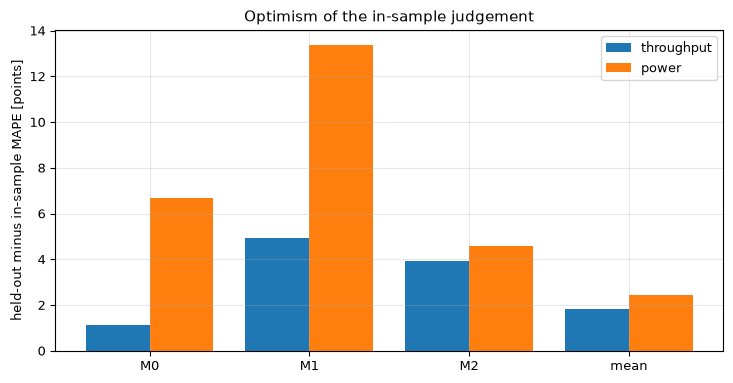

In [4]:
# Bar chart of the optimism of each model for the throughput and for the power
fig, ax = plt.subplots()
x = np.arange(len(names))
ax.bar(x - 0.2, [gap[("tph", m)] for m in names], 0.4, label="throughput")
ax.bar(x + 0.2, [gap[("kW", m)] for m in names], 0.4, label="power")
ax.set_xticks(x, [m.split("_")[0] if m != "constant_mean" else "mean" for m in names])
ax.set_ylabel("held-out minus in-sample MAPE [points]")
ax.set_title("Optimism of the in-sample judgement")
ax.legend()
fig.tight_layout()
plt.show()

For the throughput the backbone, with one fitted scalar, has the smallest optimism of the four, 1.1 points, and M1, with its ridge residual, the largest, 4.9. For the power the optimism is larger for every model: 6.7 points for the backbone, whose power form has two refitted coefficients with an in-sample optimum of the wrong sign (notebook 03 of topic 05), 13.4 for M1, and 4.6 for the free-form regression, whose held-out error is already low. The constant-mean baseline, which has no fitted parameter but the mean, still shows 1.8 and 2.5 points, a reminder that the baseline is not exempt: even a mean is fitted on a sample. The figure says how much each in-sample number must be discounted, and not which model wins; that needs the held-out values themselves, which come next.

**Step 2, the baseline.** Skill is the held-out error relative to the baseline's: a model must be below the constant mean to claim it. The cell prints, for each target, the backbone's held-out MAPE, the baseline's and the relative reduction. A negative reduction means the model is worse than guessing the mean.

In [5]:
# Relative reduction of the held-out error of the backbone against the constant-mean baseline, per target
for key, label in (("tph", "throughput"), ("kW", "power")):
    strict = doc["loo"][key]["strict"]
    backbone_error, baseline_error = strict["M0_backbone"]["mape_pct"], strict["constant_mean"]["mape_pct"]
    print(f"{label:10s} backbone {backbone_error:6.2f} %   baseline {baseline_error:6.2f} %   reduction {(baseline_error - backbone_error) / baseline_error * 100:+6.1f} %")

throughput backbone  12.09 %   baseline  18.29 %   reduction  +33.9 %
power      backbone  25.94 %   baseline  24.48 %   reduction   -6.0 %


**Step 3, the control over many seeds.** The label-shuffle control fits the residual model to permuted measurements: if it came out as good as the backbone, the residual model's apparent skill would be a leak. The committed document holds one shuffle, with one seed, and with ten points one draw says little, as notebook 03 of topic 05 showed. The cell rebuilds the document with 200 different seeds and records the held-out error of the shuffled model each time, for both targets, and counts the seeds in which it beats the backbone. The pipeline run takes a fraction of a second per seed.

In [6]:
# Rebuild CrusherCal for 200 seeds and record the held-out error of the label-shuffle control for both targets
shuffle = {"tph": [], "kW": []}
for seed in range(1, 201):
    other = loo.build(live_backbone, version, seed=seed)["loo"]
    for key in shuffle:
        shuffle[key].append(other[key]["strict"]["M1_label_shuffle"]["mape_pct"])
for key in shuffle:
    values = np.array(shuffle[key])
    reference = doc["loo"][key]["strict"]["M0_backbone"]["mape_pct"]
    print(f"{key:4s} shuffle control: mean {values.mean():6.2f} %, min {values.min():6.2f} %, max {values.max():6.2f} %  |  seeds beating the backbone: {int((values < reference).sum())} of 200")

tph  shuffle control: mean  18.36 %, min  10.45 %, max  25.76 %  |  seeds beating the backbone: 5 of 200
kW   shuffle control: mean  32.19 %, min  19.08 %, max  42.00 %  |  seeds beating the backbone: 21 of 200


The figure shows the 200 shuffled errors for the throughput as a histogram, with the backbone's held-out error as a vertical line. A control is doing its job when its distribution lies well to the right of the model's line.

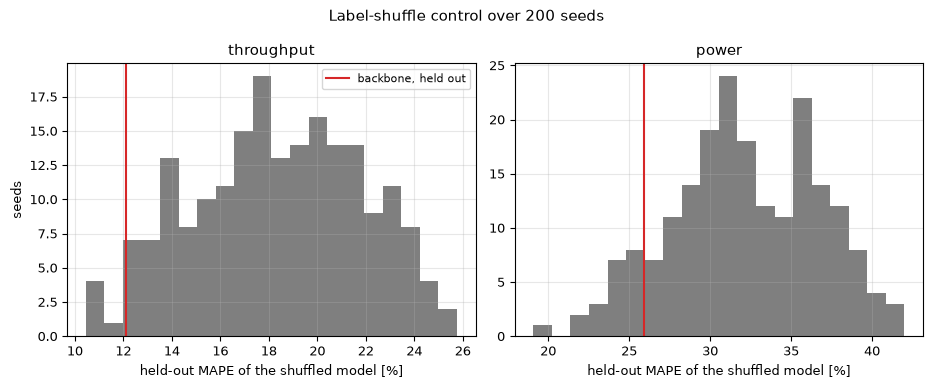

In [7]:
# Histogram of the shuffle-control error over 200 seeds, for each target, against the backbone's held-out error
fig, (left, right) = plt.subplots(1, 2, figsize=(9.4, 3.9))
for ax, key, label in ((left, "tph", "throughput"), (right, "kW", "power")):
    ax.hist(shuffle[key], bins=20, color="tab:grey")
    ax.axvline(doc["loo"][key]["strict"]["M0_backbone"]["mape_pct"], color="tab:red", lw=1.5, label="backbone, held out")
    ax.set_xlabel("held-out MAPE of the shuffled model [%]")
    ax.set_title(label)
left.set_ylabel("seeds")
left.legend(fontsize=8)
fig.suptitle("Label-shuffle control over 200 seeds")
fig.tight_layout()
plt.show()

For the throughput the backbone's line sits at the far left of the histogram: only 5 of the 200 seeds produce a shuffled model as accurate (2.5 percent), so the backbone's skill is not a leak. For the power the line sits inside the histogram, with 21 of 200 seeds (10.5 percent) doing at least as well, which is what no skill looks like. The two histograms together are the reason to run the control over many seeds: one draw at the committed seed (25.04 and 40.19 percent) would have passed both targets, and the distribution says that it should pass only one.

**Step 4, the residual model and the product size.** The bounded ridge residual M1 was pre-registered with the expectation that it would give a marginal or null improvement over the backbone, and that a null would be reported. The cell prints M1 against M0 held out for both targets. The same document scores the product size P80, which is a model output and not a measurement; its held-out error for the backbone is zero by construction, and the cell shows it so that nobody reads it as skill.

In [8]:
# Held-out MAPE of the residual model against the backbone for both targets, and the P80 self-consistency
for key in ("tph", "kW"):
    strict = doc["loo"][key]["strict"]
    print(f"{key:4s} M0 {strict['M0_backbone']['mape_pct']:6.2f} %   M1 {strict['M1_residual']['mape_pct']:6.2f} %   M1 minus M0 {strict['M1_residual']['mape_pct'] - strict['M0_backbone']['mape_pct']:+5.2f}")
print("P80, backbone held-out MAPE:", doc["loo"]["p80"]["strict"]["M0_backbone"]["mape_pct"], "%")

tph  M0  12.09 %   M1  13.45 %   M1 minus M0 +1.36
kW   M0  25.94 %   M1  25.37 %   M1 minus M0 -0.57
P80, backbone held-out MAPE: 0.0 %


## Results

**Answer:** the held-out backbone beats the constant-mean baseline for the throughput, 12.09 against 18.29 percent, a 33.9 percent reduction, and does not for the power, 25.94 against 24.48 percent, 6 percent worse than guessing the mean. The label-shuffle control over 200 seeds beats the backbone in 5 seeds for the throughput (2.5 percent) and in 21 seeds for the power (10.5 percent), so the throughput skill is not a leak and the power skill does not exist. The residual model does not beat the backbone for the throughput, 13.45 against 12.09 percent, and is marginally better for the power, 25.37 against 25.94, which is no skill either. In sample, the optimism is 1.14 points for the throughput backbone and 6.66 for the power backbone.

The first figure shows the optimism and the second the control's distribution. A validator would conclude that the product's throughput claim stands and its power claim does not, which is what the product reports; that one seed of a control is not a control; and that the free-form regression's held-out power error, 14.03 percent, is lower than any model with physics, a finding that the product does not claim a use for: the measured power tracks the setting, which a regression on the setting captures and a Bond draw does not.

## Summary

The held-out comparison separates the two targets: the throughput backbone has skill that beats a baseline and a control that is run enough times to mean something; the power backbone has none, and the free-form regression does better because it reads the setting. The numbers rest on ten surveys, and the shuffle control's own spread shows how coarse that is. The last notebook of the topic states the product's claim beyond the state of the art and measures it, including a robustness test over subsets and the calibration of a predictive band.

## References

- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919